In [1]:
import glob
import cv2
import matplotlib.pyplot as plt
from datetime import datetime
import numpy as np
from sunpy.coordinates.sun import *
from sunpy.coordinates.sun import carrington_rotation_time
import scipy.ndimage
from astropy.io import fits
from scipy import ndimage
from skimage import measure
from scipy.optimize import curve_fit
from scipy.optimize import least_squares

In [2]:
crot = 1397
cr_start = carrington_rotation_time(crot).to_datetime()
cr_end = carrington_rotation_time(crot+1).to_datetime()

/home/schatterjee/anaconda3/envs/search-ssl/lib/python3.10/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/home/schatterjee/anaconda3/envs/search-ssl/lib/python3.10/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),


In [ ]:
def hg_proj(image, date):
    image = np.flip(image,axis=0)
    xx,yy = np.meshgrid(np.linspace(0,1023,1024),
                        np.linspace(0,1023,1024))
    lat = (yy-512)*np.pi/2/512
    lon = (xx-512)*np.pi/2/512
    b_0 = B0(date).value*np.pi/180
    x = np.cos(lat)*np.sin(lon)
    y = np.sin(lat)*np.cos(b_0)-np.cos(lat)*np.cos(lon)*np.sin(b_0)
    x = np.clip(256*x + 256, 0, 511).astype(int)
    y = np.clip(256*y + 256, 0, 511).astype(int)
    hg = np.zeros((1024, 1024))
    hg = image[y,x]
    strk = np.cos(lon)**4
    return image, hg, strk

In [4]:
def car_proj(image, date, lon=30):
    _, hg, hg_strk = hg_proj(image, date)
    crlon_obs = L0(date).value
    npix = int((crlon_obs-180)/(360/2048))
    carr = np.zeros((1024,2048))
    lon_pix = int(2048*lon/360)
    carr_strk = carr.copy()
    carr[:,1024-lon_pix:1024+lon_pix] = hg[:, 512-lon_pix:512+lon_pix]
    carr_strk[:,1024-lon_pix:1024+lon_pix] = hg_strk[:, 512-lon_pix:512+lon_pix]
    carr = scipy.ndimage.shift(carr, np.array([0,npix]),mode='wrap')
    carr_strk = scipy.ndimage.shift(carr_strk, np.array([0, npix]),mode='wrap')
    return carr, carr_strk

/home/schatterjee/Downloads/cak_png/19580209_0810.png


/home/schatterjee/anaconda3/envs/search-ssl/lib/python3.10/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/home/schatterjee/anaconda3/envs/search-ssl/lib/python3.10/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),


/home/schatterjee/Downloads/cak_png/19580210_0807.png
/home/schatterjee/Downloads/cak_png/19580211_0749.png
/home/schatterjee/Downloads/cak_png/19580212_0803.png
/home/schatterjee/Downloads/cak_png/19580213_0753.png
/home/schatterjee/Downloads/cak_png/19580215_0751.png
/home/schatterjee/Downloads/cak_png/19580215_1145.png
/home/schatterjee/Downloads/cak_png/19580215_1459.png
/home/schatterjee/Downloads/cak_png/19580216_1145.png
/home/schatterjee/Downloads/cak_png/19580216_1424.png
/home/schatterjee/Downloads/cak_png/19580217_0809.png
/home/schatterjee/Downloads/cak_png/19580218_0754.png
/home/schatterjee/Downloads/cak_png/19580219_1015.png
/home/schatterjee/Downloads/cak_png/19580220_0912.png
/home/schatterjee/Downloads/cak_png/19580221_0806.png
/home/schatterjee/Downloads/cak_png/19580222_0900.png
/home/schatterjee/Downloads/cak_png/19580222_1159.png
/home/schatterjee/Downloads/cak_png/19580223_0751.png
/home/schatterjee/Downloads/cak_png/19580224_0801.png
/home/schatterjee/Downloads/

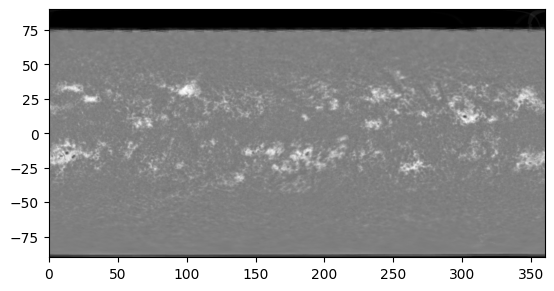

In [ ]:
dir = '/home/schatterjee/Downloads/cak_png/'
#dir = '/home/schatterjee/Downloads/ha_png/'
files = sorted(glob.glob(f'{dir}*.png'))
num = np.zeros((1024,2048))
den = num.copy()
for i in range(len(files)):
    year = int(files[i].split('/')[-1][:4])
    month = int(files[i].split('/')[-1][4:6])
    day = int(files[i].split('/')[-1][6:8])
    hour = int(files[i].split('_')[-1][:2])
    minute = int(files[i].split('_')[-1][2:4])
    dt = datetime(year, month, day, hour, minute)
    if dt<=cr_end and dt>=cr_start:
        print(files[i])
        image = cv2.imread(files[i], cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (512, 512), interpolation=cv2.INTER_AREA)
        carr,carr_strk = car_proj(image,dt,lon=30)
        num += carr*carr_strk
        den += carr_strk
plt.imshow(num/den, cmap='gray',origin='lower',extent=[0,360,-90,90])  
